In [1]:
###--------------------------------------------LOAD LIBRARIES
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import copy

In [3]:
adata =  sc.read("../../../spatialDLPFC/nonIF_c2l_anndata_combined_30samples.h5ad")

In [27]:
# Prepare data

subset = adata[adata.obs['bayesSpace_harmony_7'].isin([1,2,3,4,6])]   # Excluding WM and meningeal layers

subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)
                                                     1 : 'SpD1',
                                                     2 : 'SpD4', 
                                                     3 : 'SpD3', 
                                                     4 : 'SpD2', 
                                                     6 : 'SpD1'})

subset.obs['sample_id'] = subset.obs['sample_id'].astype(str)

df_deconvo = subset.obs[np.isnan(subset.obs['Oligo'])==False]


/tmp/ipykernel_3340880/2214811870.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)


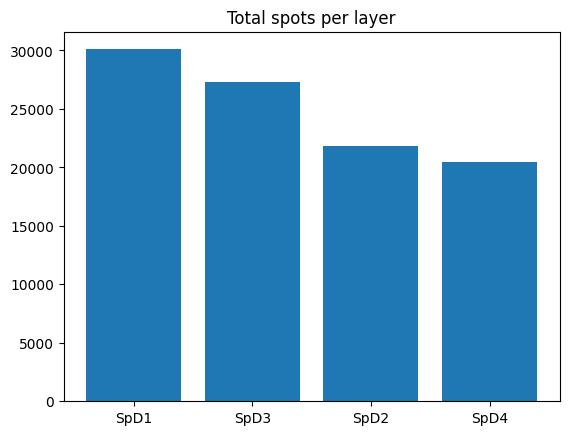

In [28]:
for_plotting = subset.obs[['sample_id', 'bayesSpace_harmony_7']].value_counts().rename('sum')
for_plotting = for_plotting.reset_index()

plt.bar(subset.obs['bayesSpace_harmony_7'].value_counts().index, subset.obs['bayesSpace_harmony_7'].value_counts())
plt.title('Total spots per layer')
plt.show()

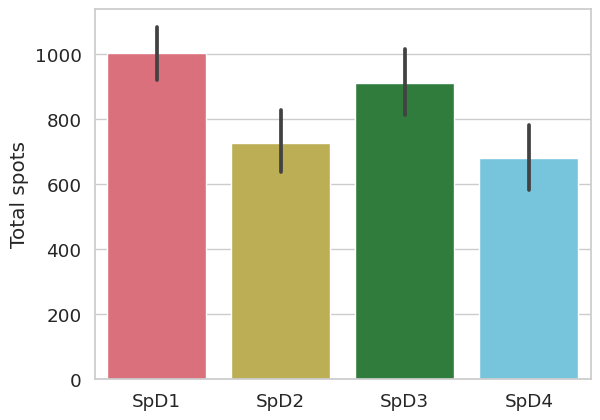

In [40]:
custom_palette = {
    'SpD1': '#ED5E70',  # blue
    'SpD2': '#CCBB44',  # orange
    'SpD3': '#238934',  # green
    'SpD4': '#66CCEE'   # red
}
sns.set(font_scale = 1.2)
sns.set_style("whitegrid")

sns.barplot(data = for_plotting, x = 'bayesSpace_harmony_7', y = 'sum', order = ['SpD1', 'SpD2', 'SpD3', 'SpD4'], palette = custom_palette)
plt.ylabel('Total spots')
plt.xlabel('')
plt.savefig('../../plots/01-4layers_withendo/07-characterise_layers/barplots_spots_per_layer.png', dpi = 300, bbox_inches = 'tight')

In [16]:
for_plotting = subset.obs[['sample_id', 'bayesSpace_harmony_7']].value_counts().rename('sum')

In [43]:
subset.obs[['bayesSpace_harmony_7', 'Astro', 'Micro', 'OPC', 'Oligo']]

,bayesSpace_harmony_7,Astro,Micro,OPC,Oligo
key,,,,,
AAACAACGAATAGTTC-1_Br6471_post-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,SpD1,0.445949,0.480911,0.348860,0.678350
AAACAAGTATCTCCCA-1_Br6471_post-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,SpD4,0.337293,0.356960,0.259246,0.206476
AAACAGAGCGACTCCT-1_Br6471_post-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,SpD1,0.401074,0.380439,0.360610,0.772953
AAACAGCTTTCAGAAG-1_Br6471_post-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,SpD4,0.252926,0.236949,0.280580,0.188901
AAACAGGGTCTATATT-1_Br6471_post-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,SpD4,0.170972,0.373516,0.196490,0.142122
...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1_Br3942_ant-1,SpD4,0.191726,0.180213,0.195571,0.175137
TTGTTCTAGATACGCT-1_Br3942_ant-1,SpD2,0.216734,0.354295,0.208155,0.131464
TTGTTGTGTGTCAAGA-1_Br3942_ant-1,SpD4,0.235637,0.224350,0.210237,0.134592
